# Player Archetype Analysis; Feature Preprocessing (Transformation & Scaling) [Milestone 3.1]

**Project Objective**:
Gather football player and team performance data across Europe's top 5 leagues to create a scouting dashboard that leverages unsupervised Machine Learning to identify statistical profiles ("player archetypes") and uncover comparable or undervalued talents.

### Milestone 3.1 Objectives:
1. Separate descriptive columns (`player_identifier`, `Player`, `Nation`, `Age`, `Pos`, `Primary_Pos`, `Squad`, `Comp`, league playing percentages) from the numeric performance feature matrix.
2. Address heavy skewed and zero-inflated distributions via Yeo-Johnson power transformations and justified (via domain knowledge) custom weighting.
3. Standardise/scale features using `StandardScaler` and evaluate against `RobustScaler`.

## Setup

In [1]:
import warnings
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler

# Add repo root to locate data directory
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

PRIMARY_POS_ORDER = ['GK', 'DF', 'MF', 'FW']

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

### Ingesting the Cleaned Featureset
Import `player_featureset.csv`, which has previously been processed by:
- Goalkeepers filtered out.
- Min 600 minutes played per club filter.
- Multi-club players aggregated.
- Metrics normalised to per-90 (with a `_p90` suffix).
- Redundant within-group features pruned.

In [2]:
featureset_path = repo_root / 'data' / 'processed' / 'player_featureset.csv'
df = pd.read_csv(featureset_path)

print(f"{df.shape[0]} players, {df.shape[1]} total columns")
print(f"Missing values: {df.isna().sum().sum()}")
df.sample(10)

1737 players, 119 total columns
Missing values: 0


,player_identifier,Player,Nation,Age,Pos,Primary_Pos,Num_Pos,Squad,Comp,passing_foot_pref,...,Car3rd_p90,CPA_p90,CarMis_p90,CarDis_p90,Fld_p90,CarProg%,CrdY_p90,CrdR_p90,2CrdY_p90,Fls_p90
860,Kamaldeen Sulemana_GHA_2002,Kamaldeen Sulemana,GHA,20,"FW, MF",MF,2,Rennes,Ligue 1,prefers right foot,...,2.837438,1.507389,2.571429,2.660099,1.862069,0.191837,0.266010,0.000000,0.000000,1.684729
1227,Nathaniel Clyne_ENG_1991,Nathaniel Clyne,ENG,31,DF,DF,1,Crystal Palace,Premier League,heavily prefers right foot,...,0.599556,0.000000,0.466321,0.199852,0.399704,0.068807,0.066617,0.000000,0.000000,0.266469
145,Antonio Sanabria_PAR_1996,Antonio Sanabria,PAR,26,FW,FW,1,Torino,Serie A,prefers right foot,...,0.948419,0.399334,4.143095,2.246256,1.747088,0.062241,0.149750,0.000000,0.000000,1.397671
1512,Sebastian Vasiliadis_GRE_1997,Sebastian Vasiliadis,GRE,24,MF,MF,1,Arminia,Bundesliga,prefers right foot,...,0.377200,0.528080,0.528080,2.414082,0.528080,0.106719,0.226320,0.000000,0.000000,1.357921
560,Giacomo Raspadori_ITA_2000,Giacomo Raspadori,ITA,22,"FW, MF",MF,2,Sassuolo,Serie A,prefers right foot,...,1.281022,0.788321,2.266423,2.167883,1.281022,0.111861,0.295620,0.032847,0.032847,0.952555
1546,Simone Verdi_ITA_1992,Simone Verdi,ITA,29,"FW, MF",FW,2,Salernitana,Serie A,indifferent,...,2.822678,1.085645,2.171291,2.171291,2.496984,0.209726,0.325694,0.000000,0.000000,1.302774
944,Liam Cooper_SCO_1991,Liam Cooper,SCO,30,DF,DF,1,Leeds United,Premier League,prefers left foot,...,0.099228,0.000000,0.297685,0.148842,0.644983,0.026316,0.248071,0.000000,0.000000,0.942668
686,Jacopo Sala_ITA_1991,Jacopo Sala,ITA,30,MF,MF,1,Spezia,Serie A,heavily prefers right foot,...,0.715909,0.000000,0.306818,1.125000,1.329545,0.057637,0.306818,0.000000,0.000000,1.636364
363,Diadie Samassekou_MLI_1996,Diadie Samassekou,MLI,26,MF,MF,1,Hoffenheim,Bundesliga,prefers right foot,...,0.761329,0.163142,1.033233,0.706949,1.577039,0.075229,0.380665,0.000000,0.000000,1.957704
1182,Moanes Dabbur_ISR_1992,Moanes Dabbur,ISR,30,"FW, MF",FW,2,Hoffenheim,Bundesliga,heavily prefers right foot,...,0.893130,0.480916,2.610687,3.366412,1.648855,0.082380,0.343511,0.000000,0.000000,2.198473


## Identify Modelling Features

The below features are purely for post-modelling analysis and dashboard filtering:
   - Player identity: `player_identifier`, `Player`, `Nation`, `Age`.
   - Positional assignments: `Pos`, `Primary_Pos`, `Num_Pos`.
   - Team & Competition context: `Squad`, `Comp`.
   - Categorical / engineered preferences: `passing_foot_pref`, `signed_preference_score`.
   - League minutes share: `Premier League_pct_mins`, `Ligue 1_pct_mins`, `Bundesliga_pct_mins`, `Serie A_pct_mins`, `La Liga_pct_mins`.

The rest are the performance metrics to be passed into the model.

In [3]:
LEAGUE_PCT_MINS_COLS = [
    'Premier League_pct_mins',
    'Ligue 1_pct_mins',
    'Bundesliga_pct_mins',
    'Serie A_pct_mins',
    'La Liga_pct_mins',
]

DESCRIPTIVE_COLS = [
    'player_identifier',
    'Player',
    'Nation',
    'Age',
    'Pos',
    'Primary_Pos',
    'Num_Pos',
    'Squad',
    'Comp',
    'passing_foot_pref',
    'signed_preference_score',
    *LEAGUE_PCT_MINS_COLS,
]


def separate_features_and_metadata(
    df: pd.DataFrame,
    metadata_cols: list[str] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Separates metadata/descriptive columns from numeric performance features."""
    if metadata_cols is None:
        metadata_cols = DESCRIPTIVE_COLS

    present_meta = [col for col in metadata_cols if col in df.columns]
    feature_cols = [col for col in df.columns if col not in present_meta]

    metadata_df = df[present_meta].copy()
    X = df[feature_cols].copy()

    # Ensure all remaining features are numeric
    non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()
    if non_numeric:
        raise ValueError(f"Non-numeric columns found in feature matrix: {non_numeric}")

    return metadata_df, X


metadata_df, X_raw = separate_features_and_metadata(df, metadata_cols=DESCRIPTIVE_COLS)

print(f"Metadata Matrix Shape:\n{metadata_df.shape}")
print(f"Numeric Feature Matrix Shape:\n{X_raw.shape}")

# Ensure only numeric cols are present
non_numeric_cols = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric_cols:
    raise ValueError(f"Non-numeric columns in feature matrix: {non_numeric_cols}")

# Preview metadata columns
print("\nDescriptive metadata columns:")
print(metadata_df.columns.tolist())
metadata_df.head(3)

Metadata Matrix Shape:
(1737, 10)
Numeric Feature Matrix Shape:
(1737, 109)

Descriptive metadata columns:
['player_identifier', 'Player', 'Nation', 'Age', 'Pos', 'Primary_Pos', 'Num_Pos', 'Squad', 'Comp', 'passing_foot_pref']


,player_identifier,Player,Nation,Age,Pos,Primary_Pos,Num_Pos,Squad,Comp,passing_foot_pref
0,Aaron Cresswell_ENG_1989,Aaron Cresswell,ENG,32,DF,DF,1,West Ham,Premier League,heavily prefers left foot
1,Aaron Hickey_SCO_2002,Aaron Hickey,SCO,19,DF,DF,1,Bologna,Serie A,indifferent
2,Aaron Lennon_ENG_1987,Aaron Lennon,ENG,35,MF,MF,1,Burnley,Premier League,heavily prefers right foot


## 3. Skewness Diagnosis & Distribution Analysis

EDA revealed that many of these metrics are heavily right skewed, and sometimes zero-inflated. For example, strikers score the majority of goals, while defenders make the majority of clearances, and only a small number of players regularly take set pieces. Other events are generally rare, such as red cards.

These heavily skewed distributions can dominate the variance in dimension reduction and the distances used to calculate clusters.

We can quantify skew (using the Fisher-Pearson skewness coefficient) to classify the level of skew across each feature. High skew may require transforming.

In [4]:
skewness_series = X_raw.skew()
abs_skewness = skewness_series.abs()

skew_summary = pd.DataFrame({
    'Metric': skewness_series.index,
    'Skewness': skewness_series.values,
    'Abs_Skewness': abs_skewness.values,
}).sort_values('Abs_Skewness', ascending=False)

symmetric_count = (abs_skewness <= 0.5).sum()
moderate_count = ((abs_skewness > 0.5) & (abs_skewness <= 1.0)).sum()
high_count = ((abs_skewness > 1.0) & (abs_skewness <= 2.0)).sum()
severe_count = (abs_skewness > 2.0).sum()

print("=== Feature Skewness Classification ===")
print(f"Approximately Symmetric (|skew| <= 0.5):        {symmetric_count:2d} features ({symmetric_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Moderately Skewed        (0.5 < |skew| <= 1.0): {moderate_count:2d} features ({moderate_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Highly Skewed            (1.0 < |skew| <= 2.0): {high_count:2d} features ({high_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Severely Skewed / Rare   (|skew| > 2.0):        {severe_count:2d} features ({severe_count/len(X_raw.columns)*100:5.1f}%)")

=== Feature Skewness Classification ===
Approximately Symmetric (|skew| <= 0.5):        26 features ( 23.9%)
Moderately Skewed        (0.5 < |skew| <= 1.0): 38 features ( 34.9%)
Highly Skewed            (1.0 < |skew| <= 2.0): 25 features ( 22.9%)
Severely Skewed / Rare   (|skew| > 2.0):        20 features ( 18.3%)


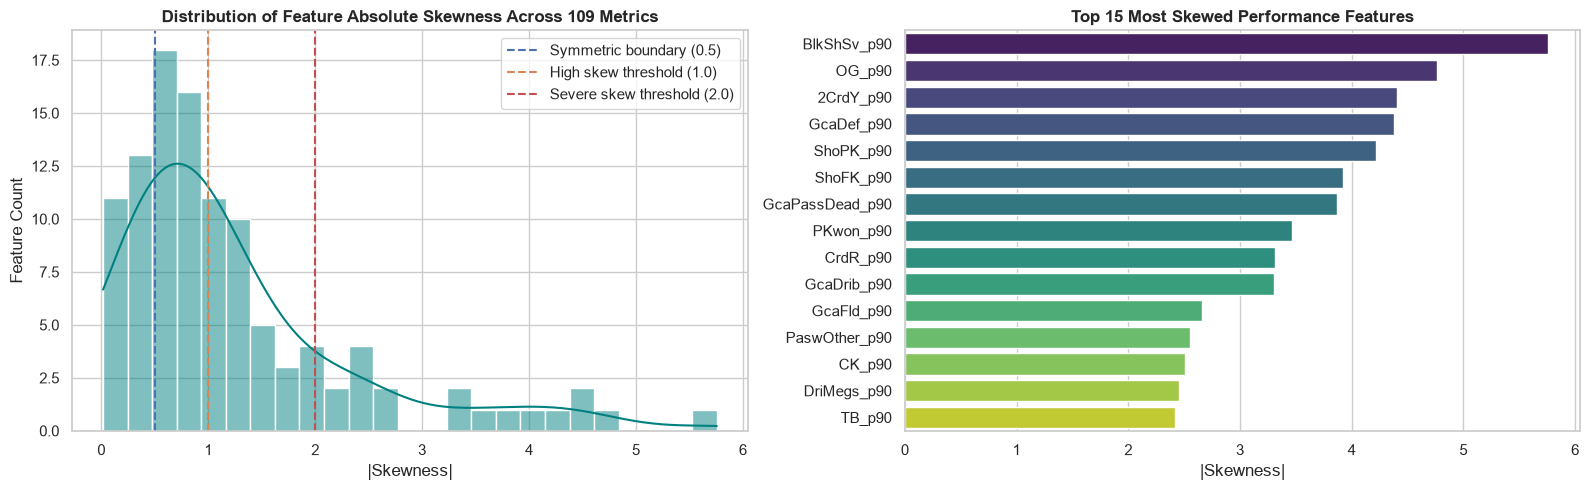

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution of absolute skewness
sns.histplot(abs_skewness, bins=25, kde=True, color='teal', ax=axes[0])
axes[0].axvline(0.5, color='#4C72B0', linestyle='--', linewidth=1.5, label='Symmetric boundary (0.5)')
axes[0].axvline(1.0, color='#DD8452', linestyle='--', linewidth=1.5, label='High skew threshold (1.0)')
axes[0].axvline(2.0, color='#C44E52', linestyle='--', linewidth=1.5, label='Severe skew threshold (2.0)')
axes[0].set_title('Distribution of Feature Absolute Skewness Across 109 Metrics', fontsize=12, fontweight='bold')
axes[0].set_xlabel('|Skewness|')
axes[0].set_ylabel('Feature Count')
axes[0].legend()

# Top 15 most skewed features
top_15_skewed = skew_summary.head(15)
sns.barplot(data=top_15_skewed, x='Abs_Skewness', y='Metric', hue='Metric', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Top 15 Most Skewed Performance Features', fontsize=12, fontweight='bold')
axes[1].set_xlabel('|Skewness|')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()


45 (41.2%) of the features are heavily skewed and will require transformation, with the majority of these being low count `_p90` metrics

## 4. Transformations

There are many ways to transform the data, but three of them are:
- **Box-Cox**; Requires strictly positive values, which cannot handle the fairly common 0 values in this data.
- **Log(x + 1)**: Unsuitable due to the fractional p90 values in the data, which will be unevenly compressed by the transformation.
- **Yeo-Johnson**: Supports <=0 values (such as `forward_pressing_index` and `forward_touch_index`), so is the most appropriate. It also has the benefit of being flexible, calculating a $\lambda$ value for each feature via Maximum Likelihood Estimation, which in turn applies a different transformation depending on the shape & skew of the data.

The latter will therefore be applied to all features exceeding the $|skew| > 1.0$ threshold.

In [6]:
def detect_skewed_features(
    X: pd.DataFrame,
    threshold: float = 1.0,
) -> list[str]:
    """Identifies features whose absolute skewness exceeds a given threshold."""
    skews = X.skew().abs()
    return skews[skews > threshold].index.tolist()


def power_transform_features(
    X: pd.DataFrame,
    columns: list[str] | None = None,
    method: str = 'yeo-johnson',
    skew_threshold: float = 1.0,
) -> tuple[pd.DataFrame, PowerTransformer]:
    """Applies power transformation to reduce skewness and stabilise variance."""
    if columns is None:
        columns = detect_skewed_features(X, threshold=skew_threshold)

    X_trans = X.copy()
    if not columns:
        transformer = PowerTransformer(method=method, standardize=False)
        return X_trans, transformer

    transformer = PowerTransformer(method=method, standardize=False)
    transformed_vals = transformer.fit_transform(X[columns])
    X_trans[columns] = transformed_vals

    return X_trans, transformer


skewed_cols = detect_skewed_features(X_raw, threshold=1.0)
print(f"Applying Yeo-Johnson transformation to {len(skewed_cols)} skewed features...")

X_transformed, pt = power_transform_features(X_raw, columns=skewed_cols, method='yeo-johnson')

skew_comparison = pd.DataFrame({
    'Metric': skewed_cols,
    'Raw_Skew': X_raw[skewed_cols].skew().values,
    'Transformed_Skew': X_transformed[skewed_cols].skew().values,
    'Fitted_Lambda': pt.lambdas_,
})
skew_comparison['Abs_Reduction'] = skew_comparison['Raw_Skew'].abs() - skew_comparison['Transformed_Skew'].abs()
skew_comparison = skew_comparison.sort_values(by='Raw_Skew', key=abs, ascending=False)

print(f"Mean absolute skewness across transformed features:")
print(f"  Raw:         {X_raw[skewed_cols].skew().abs().mean():.3f}")
print(f"  Transformed: {X_transformed[skewed_cols].skew().abs().mean():.3f}")

skew_comparison.head(15)

Applying Yeo-Johnson transformation to 45 skewed features...
Mean absolute skewness across transformed features:
  Raw:         2.211
  Transformed: 0.725


,Metric,Raw_Skew,Transformed_Skew,Fitted_Lambda,Abs_Reduction
30,BlkShSv_p90,5.755743,2.404806,-153.293957,3.350938
34,OG_p90,4.762056,3.332284,-250.333499,1.429772
44,2CrdY_p90,4.405376,3.041800,-230.823908,1.363576
13,GcaDef_p90,4.380927,2.720055,-193.744969,1.660872
16,ShoPK_p90,4.221143,2.451184,-90.570941,1.769959
15,ShoFK_p90,3.924373,1.270152,-21.444061,2.654221
18,GcaPassDead_p90,3.871277,1.829355,-68.592427,2.041922
14,PKwon_p90,3.465834,1.801632,-88.414116,1.664202
43,CrdR_p90,3.313461,1.880571,-106.170534,1.432889
10,GcaDrib_p90,3.304493,1.648192,-71.643388,1.656300


In [20]:
skewness_series = X_transformed.skew()
abs_skewness = skewness_series.abs()

skew_summary = pd.DataFrame({
    'Metric': skewness_series.index,
    'Skewness': skewness_series.values,
    'Abs_Skewness': abs_skewness.values,
}).sort_values('Abs_Skewness', ascending=False)

symmetric_count = (abs_skewness <= 0.5).sum()
moderate_count = ((abs_skewness > 0.5) & (abs_skewness <= 1.0)).sum()
high_count = ((abs_skewness > 1.0) & (abs_skewness <= 2.0)).sum()
severe_count = (abs_skewness > 2.0).sum()

still_skewed_features = list(skew_summary[skew_summary.Abs_Skewness > 1].Metric)

print("=== Feature Skewness Classification ===")
print(f"Approximately Symmetric (|skew| <= 0.5):        {symmetric_count:2d} features ({symmetric_count/len(X_transformed.columns)*100:5.1f}%)")
print(f"Moderately Skewed        (0.5 < |skew| <= 1.0): {moderate_count:2d} features ({moderate_count/len(X_transformed.columns)*100:5.1f}%)")
print(f"Highly Skewed            (1.0 < |skew| <= 2.0): {high_count:2d} features ({high_count/len(X_transformed.columns)*100:5.1f}%)")
print(f"Severely Skewed / Rare   (|skew| > 2.0):        {severe_count:2d} features ({severe_count/len(X_transformed.columns)*100:5.1f}%)")

print(f"\nStill Skewed Features  (1.0 < |skew|): [{len(still_skewed_features)} features]\n        {still_skewed_features}")


=== Feature Skewness Classification ===
Approximately Symmetric (|skew| <= 0.5):        56 features ( 51.4%)
Moderately Skewed        (0.5 < |skew| <= 1.0): 40 features ( 36.7%)
Highly Skewed            (1.0 < |skew| <= 2.0):  8 features (  7.3%)
Severely Skewed / Rare   (|skew| > 2.0):         5 features (  4.6%)

Still Skewed Features  (1.0 < |skew|): [13 features]
        ['OG_p90', '2CrdY_p90', 'GcaDef_p90', 'ShoPK_p90', 'BlkShSv_p90', 'CrdR_p90', 'GcaPassDead_p90', 'PKwon_p90', 'GcaDrib_p90', 'PKcon_p90', 'GcaFld_p90', 'ShoFK_p90', 'Err_p90']


IndexError: index 6 is out of bounds for axis 0 with size 6

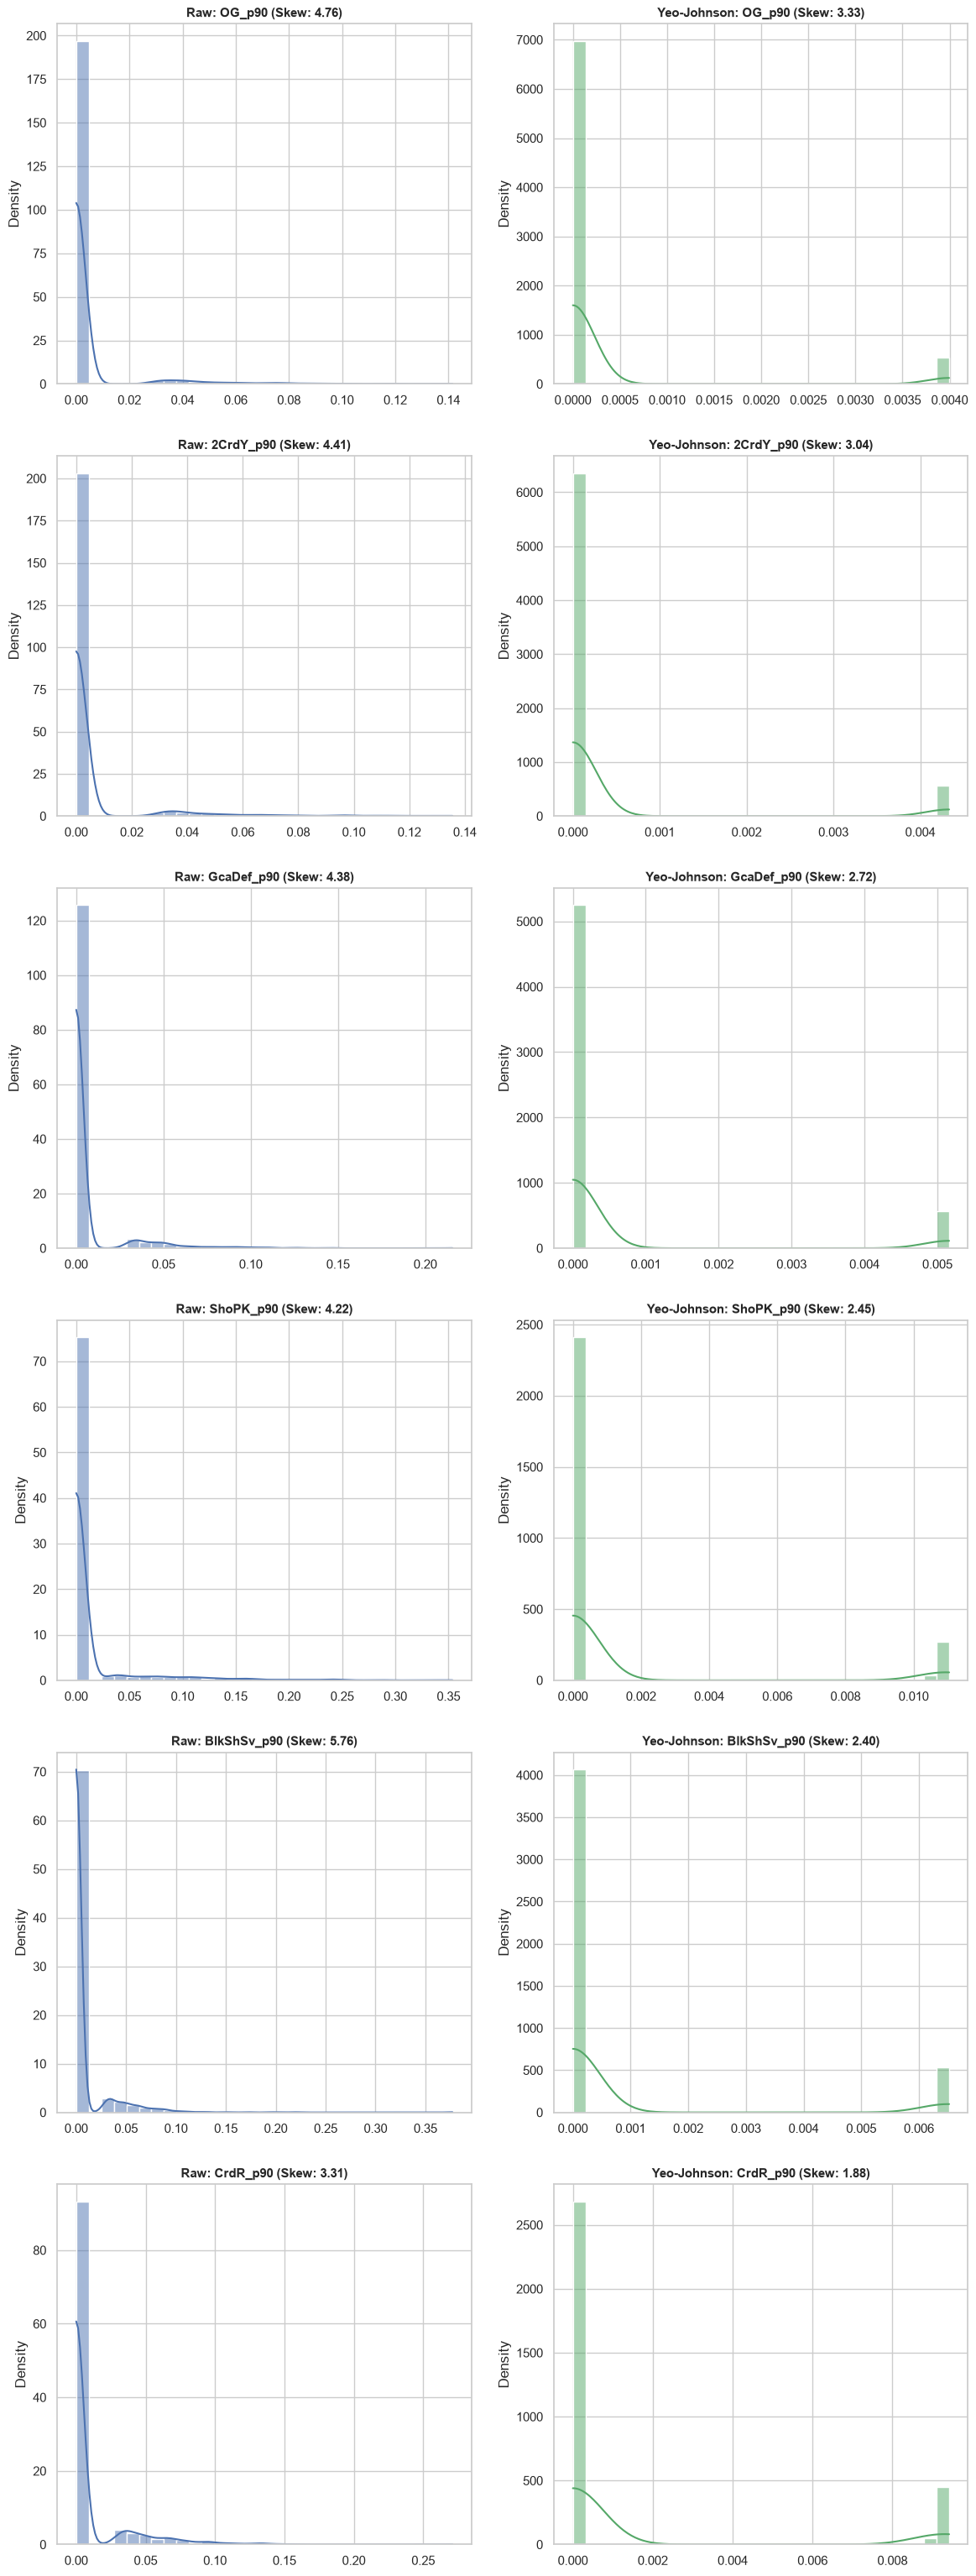

In [19]:
# Compare distribution before and after transformation
fig, axes = plt.subplots(len(sample_metrics), 2, figsize=(14, 3 * len(still_skewed_features)))

for i, col in enumerate(still_skewed_features):
    raw_s = X_raw[col].skew()
    trans_s = X_transformed[col].skew()

    sns.histplot(X_raw[col], kde=True, color='#4C72B0', ax=axes[i, 0], stat='density', bins=30)
    axes[i, 0].set_title(f"Raw: {col} (Skew: {raw_s:.2f})", fontweight='bold', fontsize=11)
    axes[i, 0].set_xlabel('')

    sns.histplot(X_transformed[col], kde=True, color='#55A868', ax=axes[i, 1], stat='density', bins=30)
    axes[i, 1].set_title(f"Yeo-Johnson: {col} (Skew: {trans_s:.2f})", fontweight='bold', fontsize=11)
    axes[i, 1].set_xlabel('')

plt.tight_layout()
plt.show()


Even after transformation, 13 columns are still heavily skewed by zero-inflation in metrics relating to uncommon actions. If left as-is, these values are likely to dominate any dimension reduction and clustering.

There are several strategies we can use to address this:
- Weighting can be applied to dampen the possible spread of a high-variance metric, such as errors, penalties conceded, or blocked shots.
- For very rare metrics (e.g. own goals), we may want to remove these; with the justification that a season or two of data is unlikely to be a high enough sample (compared to the very low counts) to determine a repeated pattern vs random events.
- Depending on the metric meaning, we could categorise into True/False (1/0) features, representing whether the player performed that action **at all** (e.g. are they a penalty taker)
- Aggregate related, low-count features (such as yellow and red cards).

Cards (yellows and reds) can be aggregated. Although simply adding the counts would lessen the increased impact of a red vs a yellow, a weighting can be applied. For example, the UEFA Fair Play calculations treat a red as 3 points, and a yellow as 1; converting to these and then summing offers an justified aggregation method, slightly reducing the zero-inflation driven impact of red cards (which are far less common than yellows).

In [ ]:
# Aggregate cards using the UEFA Fair Play definitions (red cards are worth 3 points, yellows are worth 1)

# calculate aggregated metric
# move red and yellow (and 2nd yellow) cards to meta data
